# PW8 - Logistic Regression

**Team:** Noé Berdoz, Michael Strefeler

## Our starting level

- **Noé Berdoz**: Bachelor in Business Information Technology (Informatique de gestion) at HE-Arc, completed in 2026. This programme focuses on software development and business processes and includes little mathematics, so everything in this PW was new for him, from the sigmoid and the log-likelihood to the gradient ascent and the curved decision boundaries. He had almost no experience in machine learning before this course.
- **Michael Strefeler**: Bachelor in Computer and Communication Systems (ISC) at HEIG-VD, completed in 2025, with a specialisation in data science, so he had already seen some machine learning before this course. He had already seen logistic regression in theory but had never implemented it himself, and this PW taught him new features of scikit-learn.

## Time spent

| Exercise | Time |
|---|---|
| Ex. 1 a - Linear decision boundary | 2h30 |
| Ex. 1 b - Stochastic gradient ascent (optional) | 1h |
| Ex. 1 c - Non-linear decision boundary | 1h30 |
| Ex. 1 d - Using scikit-learn | 2h |
| Ex. 2 - Classification on MNIST (optional) | 3h30 |
| Ex. 3 - Review questions | 40 min |
| **Total** | **11h10** |

## Bonus request

We would like to apply for the bonus for this PW.

**Why.** We answered every question of the three exercises, did both optional exercises and went beyond the handout where it helped us understand. For Noé, with little mathematics and almost no machine learning before this course, writing the gradient ascent of exercise 1 a step by step meant learning the sigmoid, the log-likelihood and its gradient while working, which explains the time spent. Michael used his data science background for the stochastic version in 1 b, the scikit-learn parts and the MNIST exercise. As the teacher suggested in the lecture, we re-implemented the logistic regression ourselves, reused our functions for the ten digits of MNIST, and checked each main result with a second method (scikit-learn, the teacher's reference model or a cross-validation). Each extra is listed below.

**What we did as bonus**

- **Ex. 1 a** Two extra plots (the training set, the scores before and after the z-norm), the 0.5 threshold on the sigmoid plot, a check of our weights with scikit-learn in h), and in j) the errors we share with the Gaussian naive Bayes of PW3 (8 of 11).
- **Ex. 1 b** The optional stochastic gradient ascent is done.
- **Ex. 1 c** A check with the teacher's reference model (94 correct), a 5-fold cross-validation to choose the columns without using the test set, and a test of the order of the z-norm and the squares.
- **Ex. 1 c** An explanation of why $J(\theta)$ never stops rising once the training set is separable, and of the second piece of the curve far from the data.
- **Ex. 1 d** Both a and c redone with scikit-learn and compared student by student with our own models.
- **Ex. 2** A one vs rest cross-check, and the KNN of PW2 run again with the same cross-validation folds and on the same machine, to compare the accuracy and the prediction times.
- **Ex. 2** The "daring" part, our own multi-class version built from the functions of exercise 1 (91.95%, the same as scikit-learn's one vs rest).

# Exercise 1 - Classification to predict student admission

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier

## Exercise steps

### a. Logistic regression classifier with linear decision boundary

#### a) Read the data from file

In a similar way as for the exercise of the previous week, read the training data from file `student-dataset-train.csv`. The first two columns are $x_{1}$ and $x_{2}$. The last column holds the class label $y$. Build the design matrix $X$ as follow:

$$X = \left(\begin{array}{ccc} 
        1 &   x_{1,1} & x_{1,2} \\
        1 &   \vdots  & \vdots  \\
        1 &   x_{N,1} & x_{N,2}
           \end{array}\right)$$

Check that the shape of $X$ is (100,3) and that the shape of $y$ is (100,).

            DATASET SUMMARY (TRAINING)            
- Shape of X: (100, 3)
- Shape of y: (100,)
- Class repartition: 60 admitted, 40 rejected
--------------------------------------------------
First 3 rows of X_train:
[[ 1.         34.62365962 78.02469282]
 [ 1.         30.28671077 43.89499752]
 [ 1.         35.84740877 72.90219803]]
First 3 labels of y_train:
[0 0 0]


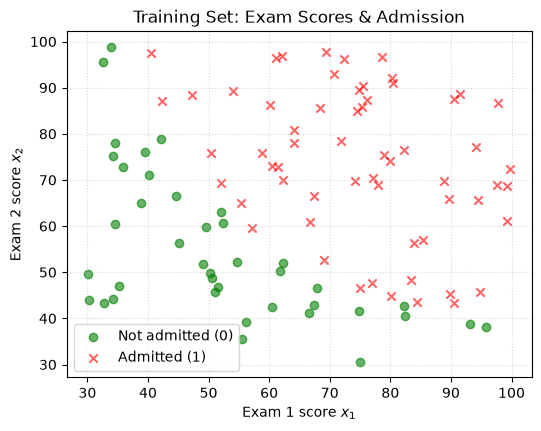

In [2]:
# Your code here
def read_data(file):
    dataset = pd.read_csv(file, names=['x1', 'x2', 'y'])
    return dataset[['x1', 'x2']].values, dataset['y'].values

x_train, y_train = read_data("student-dataset-train.csv")

N = x_train.shape[0]
X_train = np.ones((N, 3)) # column 0 stays at 1.0
X_train[:, 1] = x_train[:, 0] # exam 1
X_train[:, 2] = x_train[:, 1] # exam 2

print("=" * 50)
print(" DATASET SUMMARY (TRAINING)".center(50))
print("=" * 50)
print("- Shape of X:", X_train.shape)
print("- Shape of y:", y_train.shape)
print(f"- Class repartition: {np.sum(y_train == 1)} admitted, {np.sum(y_train == 0)} rejected")
print("-" * 50)
print("First 3 rows of X_train:")
print(X_train[:3])
print("First 3 labels of y_train:")
print(y_train[:3])
print("=" * 50)

# BONUS - a visualization with scatter plot
plt.figure(figsize=(6, 4.5))

plt.scatter(x_train[y_train == 0, 0], x_train[y_train == 0, 1],
            color='green', alpha=0.6,  marker='o', label='Not admitted (0)')

plt.scatter(x_train[y_train == 1, 0], x_train[y_train == 1, 1],
            color='red', alpha=0.6, marker='x', label='Admitted (1)')

plt.xlabel('Exam 1 score $x_1$')
plt.ylabel('Exam 2 score $x_2$')
plt.title('Training Set: Exam Scores & Admission')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

#### b) Implement a z-norm normalization of the training set

You need to store the normalization values $(\mu, \sigma)$ for later as they will be needed to normalize the test set.

         Z-SCORE NORMALIZATION (TRAINING)         
- Stored mu : [65.64, 66.22]
- Stored sigma: [19.36, 18.49]
- Mean after normalization: [-0.00, 0.00]
- Std after normalization: [1.00, 1.00]
--------------------------------------------------
First 3 rows of X_train_norm:
[[ 1.     -1.6022  0.6383]
 [ 1.     -1.8263 -1.2075]
 [ 1.     -1.539   0.3613]]


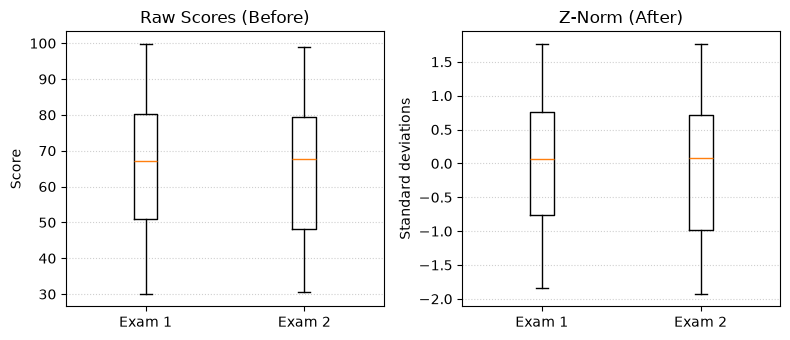

In [3]:
# Your code here
mu = np.mean(x_train, axis=0)
sigma = np.std(x_train, axis=0)

X_train_norm = np.ones((N, 3))
X_train_norm[:, 1] = (x_train[:, 0] - mu[0]) / sigma[0]
X_train_norm[:, 2] = (x_train[:, 1] -mu[1]) / sigma[1]

print("=" * 50)
print("Z-SCORE NORMALIZATION (TRAINING)".center(50))
print("=" * 50)
print(f"- Stored mu : [{mu[0]:.2f}, {mu[1]:.2f}]")
print(f"- Stored sigma: [{sigma[0]:.2f}, {sigma[1]:.2f}]")
print(f"- Mean after normalization: [{np.mean(X_train_norm[:, 1]):.2f}, {np.mean(X_train_norm[:, 2]):.2f}]")
print(f"- Std after normalization: [{np.std(X_train_norm[:, 1]):.2f}, {np.std(X_train_norm[:, 2]):.2f}]")
print("-" * 50)
print("First 3 rows of X_train_norm:")
print(np.round(X_train_norm[:3], 4))
print("=" * 50)

# BONUS - a visualization with boxplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))

# 1. Before normalization plot
ax1.boxplot(x_train, tick_labels=['Exam 1', 'Exam 2'])
ax1.set_title('Raw Scores (Before)')
ax1.set_ylabel('Score')
ax1.grid(axis='y', linestyle=':', alpha=0.6)

# After normalization plot
ax2.boxplot(X_train_norm[:, 1:], tick_labels=['Exam 1', 'Exam 2'])
ax2.set_title('Z-Norm (After)')
ax2.set_ylabel('Standard deviations')
ax2.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

#### c) Implement a sigmoid function $g(z) = \frac{1}{1+e^{-z}}$

Use numpy to compute the exp so that your function can take numpy arrays as input. Check your implementation by plotting the sigmoid function.

                 SIGMOID FUNCTION                 
- Test inputs (z)      : [-3, 0, 3]
- Output probabilities : [0.0474, 0.5, 0.9526]
- Decision pivot (z=0) : g(0) = 0.5 (boundary threshold)
- Saturated bounds     : g(-8) = 0.0003, g(8) = 0.9997


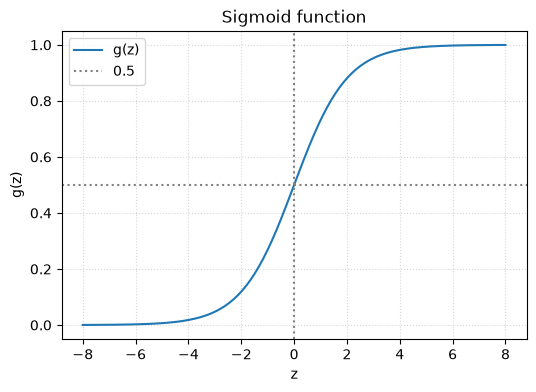

In [4]:
# Your code here
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("=" * 50)
print("SIGMOID FUNCTION".center(50))
print("=" * 50)
# Small test with the professor's input example during the course:
course_test_input  = np.array([-3, 0, 3])
print(f"- Test inputs (z)      : {course_test_input.tolist()}")
print(f"- Output probabilities : {np.round(sigmoid(course_test_input), 4).tolist()}")
print(f"- Decision pivot (z=0) : g(0) = {sigmoid(0):.1f} (boundary threshold)")
print(f"- Saturated bounds     : g(-8) = {sigmoid(-8):.4f}, g(8) = {sigmoid(8):.4f}")
print("=" * 50)

# Plot of the sigmoid curve
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 4))
plt.plot(z, sigmoid(z), label='g(z)')

# BONUS
# Show the decision threshold at P = 0.5
plt.axhline(0.5, color='gray', linestyle=':', label='0.5')
# Decision boundary pivot at z = 0 (where g(z) = 0.5)
plt.axvline(0, color='gray', linestyle=':')

plt.xlabel('z')
plt.ylabel('g(z)')
plt.title('Sigmoid function')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

#### d) Implement the hypothesis function $h_{\theta}(\mathbf{x})$

Hint: implement it so that the computation can take the full array $X$ with $h(\mathbf{x})$ broadcasted to all training samples.

In [5]:
# Your code here
def hypothesis(X, theta):
    return sigmoid(np.dot(X, theta))

h = hypothesis(X_train_norm, np.zeros(3))

print("=" * 50)
print("HYPOTHESIS FUNCTION".center(50))
print("=" * 50)
print("- Shape of h:", h.shape)
print(f"- First 3 predictions: {h[:3]}")
print(f"- Mean prediction: {np.mean(h)}")
print("=" * 50)

               HYPOTHESIS FUNCTION                
- Shape of h: (100,)
- First 3 predictions: [0.5 0.5 0.5]
- Mean prediction: 0.5


#### e) Implement the objective function $J(\theta)$

$$J(\theta) = \frac{1}{N} \sum_{n=1}^{N} y_{n} \log h_{\theta}(\mathbf{x_{n}}) + (1-y_{n}) \log (1 - h_{\theta} (\mathbf{x_{n}}))$$

In [6]:
# Your code here
def objective(X, y, theta):
    epsilon = 1e-6
    h = hypothesis(X, theta)
    N = X.shape[0]
    tmp = y * np.log(h + epsilon) + (1 - y) * np.log(1 - h + epsilon)
    return np.sum(tmp) / N

print("=" * 50)
print("OBJECTIVE FUNCTION".center(50))
print("=" * 50)
print("- Computed J at theta = 0: ", objective(X_train_norm, y_train, np.zeros(3)))
print("- Expected log(0.5): ", np.log(0.5))
print("=" * 50)

                OBJECTIVE FUNCTION                
- Computed J at theta = 0:  -0.6931451805619452
- Expected log(0.5):  -0.6931471805599453


#### f) Implement the gradient ascent

In a similar way as in PW02 and PW03, implement the gradient ascent with the update rule:

$$\theta_{i} \leftarrow \theta_{i} + \alpha \frac{1}{N} \sum_{n=1}^{N} (y_{n} - h_{\theta}(\mathbf{x}_{n})) x_{n,i}$$

In [7]:
# Your code here
def gradient_ascent(X, y, learning_rate, num_epoch):
    N = X.shape[0]
    D = X.shape[1]
    theta = np.zeros(D)
    J = []
    for epoch in range(num_epoch):
        h = hypothesis(X, theta)
        error = y - h
        gradient = np.dot(error, X) / N
        theta = theta + learning_rate * gradient
        J.append(objective(X, y, theta))
    return theta, J

learning_rate = 0.001
theta_epoch1, J1 = gradient_ascent(X_train_norm, y_train, learning_rate, num_epoch=1)

j_epoch0 = np.log(0.5)
j_epoch1 = J1[0]
delta_j = j_epoch1 - j_epoch0
print("=" * 50)
print("GRADIENT ASCENT (1 EPOCH TEST)".center(50))
print("=" * 50)
print(f"- Learning rate (alpha): {learning_rate}")
print(f"- Weights theta: theta0 = {theta_epoch1[0]:.6f}, theta1 = {theta_epoch1[1]:.6f}, theta2 = {theta_epoch1[2]:.6f}")
print(f"- Objective J (epoch0): {j_epoch0:.6f}")
print(f"- Objective J (epoch1): {j_epoch1:.6f}")
print(f"- Progression J (delta J): {delta_j:.6f}")
print("=" * 50)

          GRADIENT ASCENT (1 EPOCH TEST)          
- Learning rate (alpha): 0.001
- Weights theta: theta0 = 0.000100, theta1 = 0.000281, theta2 = 0.000251
- Objective J (epoch0): -0.693147
- Objective J (epoch1): -0.692993
- Progression J (delta J): 0.000154


#### g) Test your implementation by running a gradient ascent

Hints: use a small $\alpha$. e.g. $0.001$,  store the evolution of the objective function $J(\theta)$ during the epochs to make a plot, use a large number of epochs, e.g. $2000000$.

           MODEL TRAINING & CONVERGENCE           
- Number of epochs: 2000000
- Learning rate (alpha): 0.001
- Optimized weights: theta0 = 1.718444, theta1 = 3.992776, theta2 = 3.725125
--------------------------------------------------
- Initial J (epoch 1): -0.692993
- Checkpoint J (500k): -0.203528
- Final J (2M): -0.203496
- Total gain (delta J): +0.489497


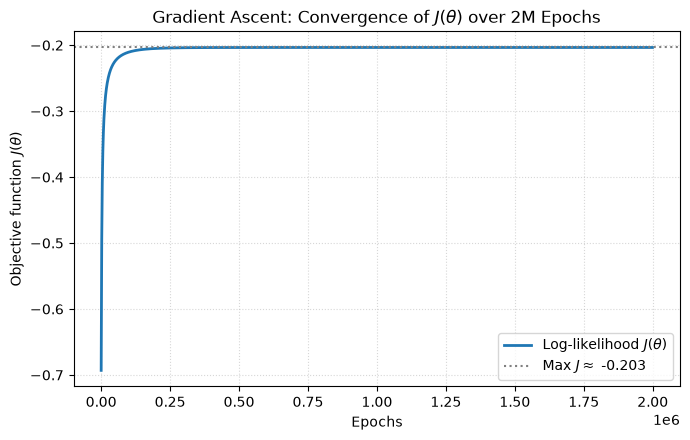

In [8]:
# Your code here
learning_rate = 0.001
num_epoch = 2000000
theta, J = gradient_ascent(X_train_norm, y_train, learning_rate, num_epoch)
print("=" * 50)
print("MODEL TRAINING & CONVERGENCE".center(50))
print("=" * 50)
print(f"- Number of epochs: {num_epoch}")
print(f"- Learning rate (alpha): {learning_rate}")
print(f"- Optimized weights: theta0 = {theta[0]:.6f}, theta1 = {theta[1]:.6f}, theta2 = {theta[2]:.6f}")
print("-" * 50)
print(f"- Initial J (epoch 1): {J[0]:.6f}")
print(f"- Checkpoint J (500k): {J[500000]:.6f}")
print(f"- Final J (2M): {J[-1]:.6f}")
print(f"- Total gain (delta J): {J[-1] - J[0]:+.6f}")
print("=" * 50)

# Convergence Visualization (subsampled every 1000 epochs for display efficiency)
step = 1000
epochs_sub = np.arange(0, num_epoch, step)
J_sub = J[::step]

plt.figure(figsize=(7, 4.5))
plt.plot(epochs_sub, J_sub, color='#1f77b4', linewidth=2, label=r'Log-likelihood $J(\theta)$')
plt.axhline(J[-1], color='gray', linestyle=':', label=rf'Max $J \approx$ {J[-1]:.3f}')

plt.xlabel('Epochs')
plt.ylabel(r'Objective function $J(\theta)$')
plt.title(r'Gradient Ascent: Convergence of $J(\theta)$ over 2M Epochs')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

#### h) Compute the correct classification rate on `student-dataset-test.csv`

Compute the correct classification rate on `student-dataset-test.csv` after convergence as you have an estimator of the posterior probabilities with:

$$P(y_{n}=1|\mathbf{x_{n}};\theta) = h_{\theta}(\mathbf{x_{n}})$$
$$P(y_{n}=0|\mathbf{x_{n}};\theta) = 1 - h_{\theta}(\mathbf{x_{n}})$$

This means that you can take the decisions $\hat{y}_{n} = 1$ if $h_{\theta}(\mathbf{x_{n}}) \geq 0.5$ and $\hat{y}_{n} = 0$ if $h_{\theta}(\mathbf{x_{n}}) < 0.5$.

In [9]:
# Your code here
x_test, y_test = read_data("student-dataset-test.csv")
N_test = x_test.shape[0]

# Normalisation using the TRAINING set statistics to avoid data leakage
X_test_norm = np.ones((N_test, 3))
X_test_norm[:, 1] = (x_test[:, 0] - mu[0]) / sigma[0]
X_test_norm[:, 2] = (x_test[:, 1] - mu[1]) / sigma[1]

# Inference with the decision rule (threshold = 0.5)
h_test = hypothesis(X_test_norm, theta)
y_pred = np.zeros(N_test)
y_pred[h_test >= 0.5] = 1

correct = np.sum(y_pred == y_test)
missed = N_test - correct
accuracy = (correct / N_test) * 100

# Bonus independent cross-check using scikit-learn (unregularized)
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(C=np.inf, tol=1e-10)
clf.fit(X_train_norm[:, 1:], y_train)  # scikit-learn fits its own intercept
y_pred_sklearn = clf.predict(X_test_norm[:, 1:])
sklearn_correct = int(np.sum(y_pred_sklearn == y_test))
sk_t0 = round(float(clf.intercept_[0]), 4)
sk_t1 = round(float(clf.coef_[0][0]), 4)
sk_t2 = round(float(clf.coef_[0][1]), 4)

t0 = round(float(theta[0]), 4)
t1 = round(float(theta[1]), 4)
t2 = round(float(theta[2]), 4)

print("=" * 50)
print("TEST EVALUATION & BENCHMARK".center(50))
print("=" * 50)
print("- Test samples            :", N_test)
print("- Decision rule           : y_hat = 1 if h >= 0.5")
print("-" * 50)
print("SCRATCH IMPLEMENTATION")
print("- Correct classifications :", correct, "/", N_test)
print("- Misclassifications      :", missed, "/", N_test)
print("- Classification rate     :", round(accuracy, 2), "%")
print("-" * 50)
print("SCIKIT-LEARN BENCHMARK")
print("- Weights (scratch)       :", [t0, t1, t2])
print("- Weights (sklearn)       :", [sk_t0, sk_t1, sk_t2])
print("- Test accuracy match     :", sklearn_correct, "/", N_test)
print("=" * 50)

           TEST EVALUATION & BENCHMARK            
- Test samples            : 100
- Decision rule           : y_hat = 1 if h >= 0.5
--------------------------------------------------
SCRATCH IMPLEMENTATION
- Correct classifications : 89 / 100
- Misclassifications      : 11 / 100
- Classification rate     : 89.0 %
--------------------------------------------------
SCIKIT-LEARN BENCHMARK
- Weights (scratch)       : [1.7184, 3.9928, 3.7251]
- Weights (sklearn)       : [1.7184, 3.9928, 3.7251]
- Test accuracy match     : 89 / 100


#### i) Draw the decision boundary

Draw the decision boundary of your system on top of the scatter plot of the testing data.

          DECISION BOUNDARY ON TEST SET           
- Pivot condition: z = theta^T * X = 0  (P = 0.5)
- Linear boundary equation: x2' = -(theta0 + theta1*x1') / theta2
--------------------------------------------------
- Boundary at Exam 1 = 20 : Exam 2 = 104.42
- Boundary at Exam 1 = 105: Exam 2 = 17.41


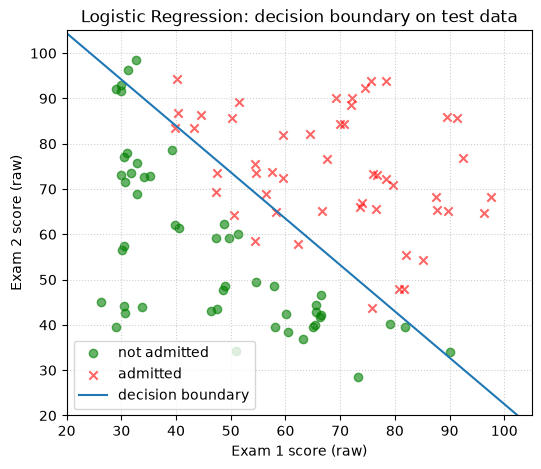

In [10]:
# Your code here
x1_line = np.linspace(20, 105, 100) # exam 1, raw score
x1n_line = (x1_line - mu[0]) / sigma[0] # normalised
x2n_line = -(theta[0] + theta[1] * x1n_line) / theta[2]
x2_line = mu[1] + sigma[1] * x2n_line # back to a raw score

print("=" * 50)
print("DECISION BOUNDARY ON TEST SET".center(50))
print("=" * 50)
print("- Pivot condition: z = theta^T * X = 0  (P = 0.5)")
print("- Linear boundary equation: x2' = -(theta0 + theta1*x1') / theta2")
print("-" * 50)
print("- Boundary at Exam 1 = 20 : Exam 2 =", round(float(x2_line[0]), 2))
print("- Boundary at Exam 1 = 105: Exam 2 =", round(float(x2_line[-1]), 2))
print("=" * 50)

# Scatter plot of test set with decision boundary
plt.figure(figsize=(6, 5))
plt.scatter(x_test[y_test == 0, 0], x_test[y_test == 0, 1], color='green', alpha=0.6,  marker='o', label='not admitted')
plt.scatter(x_test[y_test == 1, 0], x_test[y_test == 1, 1], color='red', alpha=0.6, marker='x', label='admitted')

plt.plot(x1_line, x2_line, label='decision boundary')

plt.xlim(20, 105)
plt.ylim(20, 105)
plt.xlabel('Exam 1 score (raw)')
plt.ylabel('Exam 2 score (raw)')
plt.title('Logistic Regression: decision boundary on test data')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

#### j) Compare the performance

Compare the performance of the logistic regression system with the ones of previous's week.

In [11]:
# Check for j): the Gaussian naive Bayes of PW3, with scikit-learn, on the same files
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB().fit(x_train, y_train)
y_pred_gnb = gnb.predict(x_test)
y_pred_lr = (hypothesis(X_test_norm, theta) >= 0.5).astype(int)

errors_gnb = set(np.where(y_pred_gnb != y_test)[0])
errors_lr = set(np.where(y_pred_lr != y_test)[0])

print("=" * 50)
print("PW3 GAUSSIAN NAIVE BAYES VS LOGISTIC REGRESSION".center(50))
print("=" * 50)
print("- Gaussian naive Bayes, test correct:", int(np.sum(y_pred_gnb == y_test)), "/", N_test)
print("- Logistic regression, test correct :", int(np.sum(y_pred_lr == y_test)), "/", N_test)
print("- Errors shared by the two systems  :", len(errors_gnb & errors_lr), "of", len(errors_lr))
print("=" * 50)

 PW3 GAUSSIAN NAIVE BAYES VS LOGISTIC REGRESSION  
- Gaussian naive Bayes, test correct: 89 / 100
- Logistic regression, test correct : 89 / 100
- Errors shared by the two systems  : 8 of 11


As we used the same train and test files as in PW3 exercise 1, the numbers compare directly:

| System (test set, 100 students) | Accuracy |
|---|---|
| PW3 Bayes, exam 1 only (histogram) | 0.70 |
| PW3 Bayes, exam 2 only (histogram) | 0.73 |
| PW3 naive Bayes, both exams (histogram, frequency per bin) | 0.88 |
| PW3 naive Bayes, both exams (Gaussian) | 0.89 |
| PW8 logistic regression, linear boundary | 0.89 |

With both exams, the three systems are within one student out of 100.
This gap is too small to say that one system is better.
Logistic regression and the Gaussian naive Bayes even share 8 of their 11 errors.

The two methods do not model the same thing.
Bayes models how the scores are spread inside each class, then uses Bayes rule to get the posterior.
Logistic regression estimates $P(y=1 \mid x)$ directly, with only 3 weights.

So on this data, the choice of method does not change the performance.
The errors come from students who sit among the other class, and no straight boundary can classify them.

But on other data, the choice can matter.
In lecture 3 we saw that Bayes keeps the priors $P(C_k)$ separate, so it handles unbalanced classes well and we can change the priors without retraining.
Logistic regression learns only the border. This makes it faster at inference, but it must be retrained if the priors change.
It also means that we can make the border curved by adding columns such as $x_1^2$ and $x_2^2$.

### b. Optional - Stochastic gradient ascent

Redo the experiments of 2.a with a stochastic gradient ascent.

In [12]:
# Your code here
def stochastic_gradient_ascent(X, y, alpha=0.001, max_epochs=2_000_000, epsilon=1e-6, seed=None, verbose=True):
    rng = np.random.default_rng(seed)
    N, D = X.shape

    thetas = np.zeros(D)

    # History used for plots, recorded once per epoch
    J_history = [objective(X, y, thetas)]   # J(theta) after each epoch
    theta_history = [thetas.copy()]         # thetas after each epoch

    for epoch in range(1, max_epochs + 1):
        # One epoch = N updates, each on 1 randomly drawn sample
        for _ in range(N):
            n = rng.integers(N)
            x_n = X[n]
            y_n = y[n]
            # Gradient of J for a single sample: (y_n - h(x_n)) * x_n
            thetas = thetas + alpha * (y_n - hypothesis(x_n, thetas)) * x_n

        # Convergence check on the full training set, once per epoch
        J = objective(X, y, thetas)
        J_history.append(J)
        theta_history.append(thetas.copy())

        if not np.isfinite(J):
            print("Diverged: try a smaller alpha")
            break

        # Relative change |J^(n) - J^(n-1)| / |J^(n)|
        rel_change = abs(J - J_history[-2]) / abs(J)
        if verbose and epoch % 100 == 0:
            print(f"epoch {epoch}: J = {J:.6f}, rel. change = {rel_change:.2e}, thetas = {np.round(thetas, 3)}")
        if rel_change < epsilon:
            print(f"Stopped after {epoch} epochs ({epoch * N} updates)")
            break

    return thetas, np.array(J_history), np.array(theta_history)

epoch 100: J = -0.312482, rel. change = 3.03e-03, thetas = [0.479 1.282 1.142]
epoch 200: J = -0.262458, rel. change = 1.15e-03, thetas = [0.701 1.776 1.588]
epoch 300: J = -0.241983, rel. change = 5.60e-04, thetas = [0.804 2.096 1.897]
epoch 400: J = -0.231139, rel. change = 1.75e-04, thetas = [0.888 2.33  2.117]
epoch 500: J = -0.224556, rel. change = 4.24e-04, thetas = [0.983 2.498 2.275]
epoch 600: J = -0.219622, rel. change = 8.40e-05, thetas = [1.08  2.652 2.414]
epoch 700: J = -0.216581, rel. change = 1.25e-04, thetas = [1.158 2.747 2.532]
epoch 800: J = -0.214220, rel. change = 8.08e-05, thetas = [1.205 2.857 2.619]
Stopped after 847 epochs (84700 updates)
- Final thetas: [1.2395 2.91   2.6502]
- Final J: -0.213309
- Training accuracy: 89.00%


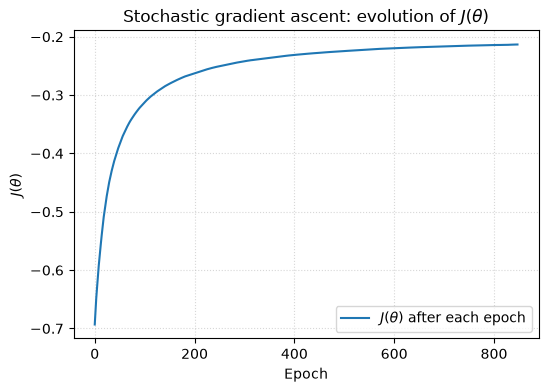

In [13]:
thetas_sga, J_hist_sga, theta_hist_sga = stochastic_gradient_ascent(X_train_norm, y_train, alpha=0.001, seed=0)

train_acc = np.mean((hypothesis(X_train_norm, thetas_sga) >= 0.5) == y_train)
print(f"- Final thetas: {np.round(thetas_sga, 4)}")
print(f"- Final J: {J_hist_sga[-1]:.6f}")
print(f"- Training accuracy: {train_acc:.2%}")

plt.figure(figsize=(6, 4))
plt.plot(J_hist_sga, label=r'$J(\theta)$ after each epoch')
plt.xlabel('Epoch')
plt.ylabel(r'$J(\theta)$')
plt.title('Stochastic gradient ascent: evolution of $J(\\theta)$')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

In [14]:
# Correct classification rate on the test set
x_test, y_test = read_data("student-dataset-test.csv")

# Normalize the test set with the mu and sigma of the TRAINING set
N_test = x_test.shape[0]
X_test_norm = np.ones((N_test, 3))
X_test_norm[:, 1] = (x_test[:, 0] - mu[0]) / sigma[0]
X_test_norm[:, 2] = (x_test[:, 1] - mu[1]) / sigma[1]

# Decision: y_hat = 1 if h(x) >= 0.5, else 0
y_pred_sga = (hypothesis(X_test_norm, thetas_sga) >= 0.5).astype(int)
test_acc_sga = np.mean(y_pred_sga == y_test)

print("=" * 50)
print("STOCHASTIC GRADIENT ASCENT - TEST SET".center(50))
print("=" * 50)
print(f"- Correct classification rate: {test_acc_sga:.2%} ({np.sum(y_pred_sga == y_test)}/{N_test})")
print(f"- Misclassified samples: {np.sum(y_pred_sga != y_test)}")
print("=" * 50)

      STOCHASTIC GRADIENT ASCENT - TEST SET       
- Correct classification rate: 89.00% (89/100)
- Misclassified samples: 11


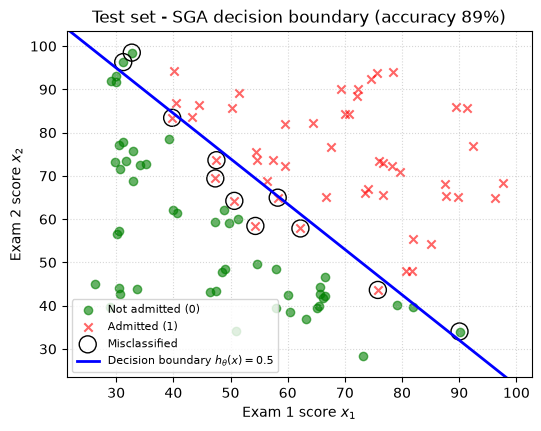

In [15]:
# Decision boundary: h(x) = 0.5  <=>  theta_0 + theta_1 * z1 + theta_2 * z2 = 0
# with z = (x - mu) / sigma, so solving for x2 in original units:
# x2 = mu2 - sigma2 / theta_2 * (theta_0 + theta_1 * (x1 - mu1) / sigma1)
def decision_boundary_x2(x1, thetas, mu, sigma):
    z1 = (x1 - mu[0]) / sigma[0]
    z2 = -(thetas[0] + thetas[1] * z1) / thetas[2]
    return mu[1] + sigma[1] * z2

x1_line = np.linspace(x_test[:, 0].min() - 5, x_test[:, 0].max() + 5, 100)
x2_line = decision_boundary_x2(x1_line, thetas_sga, mu, sigma)

plt.figure(figsize=(6, 4.5))
plt.scatter(x_test[y_test == 0, 0], x_test[y_test == 0, 1],
            color='green', alpha=0.6, marker='o', label='Not admitted (0)')
plt.scatter(x_test[y_test == 1, 0], x_test[y_test == 1, 1],
            color='red', alpha=0.6, marker='x', label='Admitted (1)')

# Circle the misclassified test samples
wrong = y_pred_sga != y_test
plt.scatter(x_test[wrong, 0], x_test[wrong, 1], s=150, facecolors='none',
            edgecolors='black', label='Misclassified')

plt.plot(x1_line, x2_line, color='blue', lw=2, label=r'Decision boundary $h_\theta(x)=0.5$')

plt.xlim(x_test[:, 0].min() - 5, x_test[:, 0].max() + 5)
plt.ylim(x_test[:, 1].min() - 5, x_test[:, 1].max() + 5)
plt.xlabel('Exam 1 score $x_1$')
plt.ylabel('Exam 2 score $x_2$')
plt.title(f'Test set - SGA decision boundary (accuracy {test_acc_sga:.0%})')
plt.legend(loc='lower left', fontsize=8)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

With the stochastic version, our stopping rule ends the training after 847 epochs, when the relative change of $J(\theta)$ between two epochs is below $10^{-6}$.
But $J(\theta)$ is still at -0.2133, below the -0.2035 of exercise a, so the training stopped a bit early.
Each update uses one student drawn at random, so $J(\theta)$ moves a little at each epoch, and one small change is enough to stop the training.
For the test set this changes nothing. We get 89 of 100, and in exercise d scikit-learn gives the same prediction as a and as b for every test student.

### c. Logistic regression classifier with non-linear decision boundary

Redo the experiments of 2.a by increasing the complexity of the model in order to have a non-linear decision boundary:

$$h_{\theta}(\mathbf{x}) = g(\theta_{0} + \theta_{1} x_{1} + \theta_{2} x_{2} + \theta_{3} x_{1}^{2} + \theta_{4} x_{2}^{2} + \theta_{5} x_{1}x_{2} + \ldots)$$

In [16]:
# Your code here
def poly_features(x):
    x1_norm = (x[:, 0] - mu[0]) / sigma[0]
    x2_norm = (x[:, 1] - mu[1]) / sigma[1]
    ones = np.ones(x.shape[0])

    return np.column_stack((ones, x1_norm, x2_norm, x1_norm ** 2, x2_norm ** 2, x1_norm * x2_norm))

X_poly = poly_features(x_train)
X_poly_test = poly_features(x_test)

print("=" * 50)
print("POLYNOMIAL FEATURES (DEGREE 2)".center(50))
print("=" * 50)
print("- Train shape: ", X_poly.shape)
print("- Test shape: ", X_poly_test.shape)
print("- Sample 0: ", np.round(X_poly[0], 3))
print("=" * 50)

# BONUS
# Impact of normalization order on feature collinearity
F_raw = np.column_stack((x_train, x_train**2))
mu_F, sigma_F = np.mean(F_raw, axis=0), np.std(F_raw, axis=0)
X_raw_norm = (F_raw - mu_F) / sigma_F

corr_raw_first = np.corrcoef(X_raw_norm[:, 0], X_raw_norm[:, 2])[0, 1]
corr_norm_first = np.corrcoef(X_poly[:, 1], X_poly[:, 3])[0, 1]

print("=" * 50)
print("FEATURE COLLINEARITY ANALYSIS".center(50))
print("=" * 50)
print("- Corr(x1, x1^2) [Square then Norm]: ", round(float(corr_raw_first), 3))
print("- Corr(x1, x1^2) [Norm then Square]: ", round(float(corr_norm_first), 3))
print("=" * 50)

          POLYNOMIAL FEATURES (DEGREE 2)          
- Train shape:  (100, 6)
- Test shape:  (100, 6)
- Sample 0:  [ 1.    -1.602  0.638  2.567  0.407 -1.023]
          FEATURE COLLINEARITY ANALYSIS           
- Corr(x1, x1^2) [Square then Norm]:  0.989
- Corr(x1, x1^2) [Norm then Square]:  -0.094


We z-norm $x_1$ and $x_2$ first, with the $\mu$ and $\sigma$ of exercise a, then we compute the new columns from the z-normed scores.
The order matters for the gradient ascent.
The raw scores are all positive, so $x_1^2$ grows almost like $x_1$, and after the z-norm the two columns are nearly the same (correlation 0.989).
When $x_1$ is z-normed first, it is negative below the mean and positive above, so $x_1^2$ is no longer a copy of $x_1$ (correlation -0.094).
The bonus at the end of this section shows what this changes for the training.

            MODEL TRAINING (6 COLUMNS)            
- Number of epochs: 2000000
- Learning rate (alpha): 0.001
- Optimized weights: [ 9.2544  8.7678  8.9216 -4.646  -3.1367 -2.825 ]
--------------------------------------------------
- J after 500k epochs: -0.0797
- J after 1M epochs  : -0.0603
- J after 2M epochs  : -0.0445
- Final J of exercise a (straight line): -0.2035


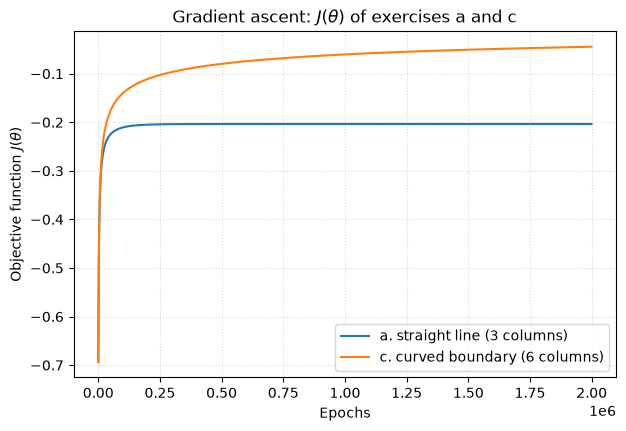

In [17]:
# Training with the new columns
# Same settings as in exercise a: theta = 0 at the start, alpha = 0.001, 2 000 000 epochs
learning_rate = 0.001
num_epoch = 2000000
theta_poly, J_poly = gradient_ascent(X_poly, y_train, learning_rate, num_epoch)

print("=" * 50)
print("MODEL TRAINING (6 COLUMNS)".center(50))
print("=" * 50)
print(f"- Number of epochs: {num_epoch}")
print(f"- Learning rate (alpha): {learning_rate}")
print("- Optimized weights:", np.round(theta_poly, 4))
print("-" * 50)
print(f"- J after 500k epochs: {J_poly[499999]:.4f}")
print(f"- J after 1M epochs  : {J_poly[999999]:.4f}")
print(f"- J after 2M epochs  : {J_poly[-1]:.4f}")
print(f"- Final J of exercise a (straight line): {J[-1]:.4f}")
print("=" * 50)

# J of both models, every 1000 epochs
step = 1000
epochs_sub = np.arange(0, num_epoch, step)

plt.figure(figsize=(7, 4.5))
plt.plot(epochs_sub, J[::step], label='a. straight line (3 columns)')
plt.plot(epochs_sub, J_poly[::step], label='c. curved boundary (6 columns)')
plt.xlabel('Epochs')
plt.ylabel(r'Objective function $J(\theta)$')
plt.title(r'Gradient ascent: $J(\theta)$ of exercises a and c')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

With the new columns, J ends much higher than with the straight line, -0.0445 against -0.2035.
But J does not stop rising. It still goes up between 1 000 000 and 2 000 000 epochs, while the J of exercise a is flat.

The reason is that with the squares, a curve can separate the two classes of the training set without a mistake (the next cell gets 100 of the 100 training students right after 500 000 epochs).
In that case J has no maximum.
If we take a $\theta$ that makes no mistake on the training set, like the one after 500 000 epochs, and multiply it by a larger number, the boundary $h_\theta(x) = 0.5$ stays at the same place, but every $h_\theta(x)$ gets closer to 0 or 1, so J gets closer to 0.
The gradient ascent keeps making $\theta$ larger for as long as we let it run.
After 2 000 000 epochs, one training student is on the wrong side of the curve (99 of 100 in the next cell).
This can happen because the gradient ascent makes J larger, not the number of correct students.

In [18]:
# Correct classification rate on the test set
def count_correct(X, y, theta):
    y_pred = np.zeros(X.shape[0])
    y_pred[hypothesis(X, theta) >= 0.5] = 1
    return int(np.sum(y_pred == y))

# The same model stopped after 500 000 epochs, to see if the number of epochs changes the result
theta_500k, J_500k = gradient_ascent(X_poly, y_train, learning_rate, 500000)

correct_poly = count_correct(X_poly_test, y_test, theta_poly)

print("=" * 50)
print("TEST EVALUATION (6 COLUMNS)".center(50))
print("=" * 50)
print("- Decision rule: y_hat = 1 if h >= 0.5")
print("-" * 50)
print("AFTER 2 000 000 EPOCHS")
print("- Train correct          :", count_correct(X_poly, y_train, theta_poly), "/", N)
print("- Test correct           :", correct_poly, "/", N_test)
print("- Classification rate    :", round(correct_poly / N_test * 100, 2), "%")
print("-" * 50)
print("AFTER 500 000 EPOCHS")
print("- Train correct          :", count_correct(X_poly, y_train, theta_500k), "/", N)
print("- Test correct           :", count_correct(X_poly_test, y_test, theta_500k), "/", N_test)
print("-" * 50)
print("STRAIGHT LINE OF EXERCISE a (2 000 000 EPOCHS)")
print("- Test correct           :", count_correct(X_test_norm, y_test, theta), "/", N_test)
print("=" * 50)

           TEST EVALUATION (6 COLUMNS)            
- Decision rule: y_hat = 1 if h >= 0.5
--------------------------------------------------
AFTER 2 000 000 EPOCHS
- Train correct          : 99 / 100
- Test correct           : 95 / 100
- Classification rate    : 95.0 %
--------------------------------------------------
AFTER 500 000 EPOCHS
- Train correct          : 100 / 100
- Test correct           : 94 / 100
--------------------------------------------------
STRAIGHT LINE OF EXERCISE a (2 000 000 EPOCHS)
- Test correct           : 89 / 100


After 2 000 000 epochs, the curved model classifies 95 of the 100 test students correctly, against 89 with the straight line of exercise a.
It is also better than all the systems of PW3 in the table of j), where the best one had an accuracy of 0.89.
The number of epochs changes the result a little. After 500 000 epochs we get 94 on the test set.
Since J never stops rising, there is no "end" of the training, so we report the number of epochs with the result and keep the 2 000 000 epochs of exercise a.

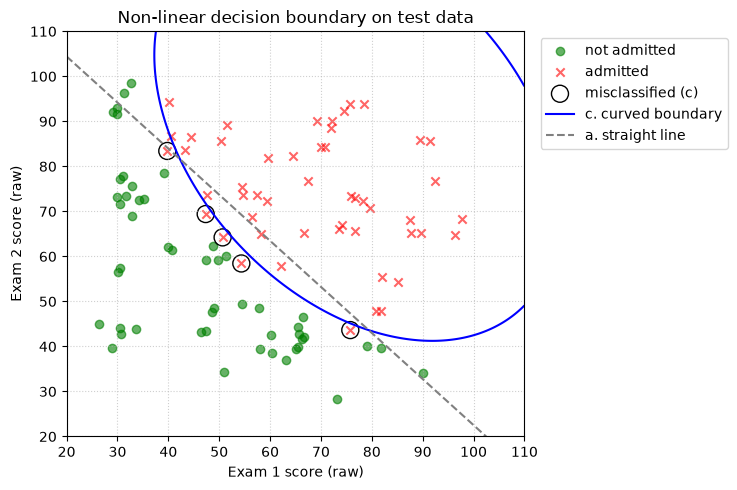

In [19]:
# Decision boundary on the test set
# The boundary is no longer a straight line, so we cannot solve it for x2 as in i).
# We compute h on a grid of exam scores and draw the line where h = 0.5 (a contour).
x1_grid = np.linspace(20, 110, 300)
x2_grid = np.linspace(20, 110, 300)
X1g, X2g = np.meshgrid(x1_grid, x2_grid)
grid_points = np.column_stack((X1g.ravel(), X2g.ravel()))
H = hypothesis(poly_features(grid_points), theta_poly).reshape(X1g.shape)

# Straight line of exercise a, for comparison (same formula as in i)
x1_line_a = np.linspace(20, 110, 100)
x2_line_a = mu[1] + sigma[1] * (-(theta[0] + theta[1] * (x1_line_a - mu[0]) / sigma[0]) / theta[2])

# Test students that the curved model gets wrong
wrong_poly = (hypothesis(X_poly_test, theta_poly) >= 0.5) != (y_test == 1)

plt.figure(figsize=(7.5, 5))
plt.scatter(x_test[y_test == 0, 0], x_test[y_test == 0, 1], color='green', alpha=0.6, marker='o', label='not admitted')
plt.scatter(x_test[y_test == 1, 0], x_test[y_test == 1, 1], color='red', alpha=0.6, marker='x', label='admitted')
plt.scatter(x_test[wrong_poly, 0], x_test[wrong_poly, 1], s=150, facecolors='none', edgecolors='black', label='misclassified (c)')
plt.contour(X1g, X2g, H, levels=[0.5], colors='blue')
plt.plot([], [], color='blue', label='c. curved boundary')  # a contour has no label of its own
plt.plot(x1_line_a, x2_line_a, color='gray', linestyle='--', label='a. straight line')

plt.xlim(20, 110)
plt.ylim(20, 110)
plt.xlabel('Exam 1 score (raw)')
plt.ylabel('Exam 2 score (raw)')
plt.title('Non-linear decision boundary on test data')
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [20]:
# Test students where the straight line of a and the curve of c do not agree
pred_a = (hypothesis(X_test_norm, theta) >= 0.5).astype(int)
pred_c = (hypothesis(X_poly_test, theta_poly) >= 0.5).astype(int)
fixed = np.where((pred_a != y_test) & (pred_c == y_test))[0]
added = np.where((pred_a == y_test) & (pred_c != y_test))[0]
kept = np.where((pred_a != y_test) & (pred_c != y_test))[0]

print("=" * 50)
print("STRAIGHT LINE (a) AGAINST CURVE (c), TEST SET".center(50))
print("=" * 50)
print("- Errors of a that c fixes:", len(fixed))
for n in fixed:
    print(f"  ({x_test[n, 0]:.1f}, {x_test[n, 1]:.1f}), admitted = {y_test[n]}")
print("- New errors of c:", len(added))
print("- Errors of a that c keeps:", len(kept))
print("-" * 50)
print(f"- h for a student with 110 on both exams: {hypothesis(poly_features(np.array([[110, 110]])), theta_poly)[0]:.4f}")
print("=" * 50)

  STRAIGHT LINE (a) AGAINST CURVE (c), TEST SET   
- Errors of a that c fixes: 6
  (58.3, 65.0), admitted = 1
  (90.1, 34.0), admitted = 0
  (32.7, 98.5), admitted = 0
  (47.5, 73.6), admitted = 1
  (31.2, 96.3), admitted = 0
  (62.2, 57.8), admitted = 1
- New errors of c: 0
- Errors of a that c keeps: 5
--------------------------------------------------
- h for a student with 110 on both exams: 0.0011


The cell above compares the two models on the test set. The curve fixes 6 of the 11 errors of the straight line and adds no new one.
Three of them are refused students with very unbalanced scores, at (32.7, 98.5), (31.2, 96.3) and (90.1, 34.0).
The straight line admitted them, because one very high score made up for the very low one.
The curve refuses them. With the curve, a student needs two scores that are both good enough to be admitted.
The other three are admitted students in the middle of the plot, that the curve now puts on the correct side.
The 5 errors that remain were also errors of the straight line. These students are close to the boundary, where the two classes mix.

The boundary looks like part of an ellipse, and the model admits the students inside it.
This is why a small second piece of the curve appears in the top right corner. A student with 110 on both exams would be refused ($h_\theta(x) = 0.0011$).
No student of the dataset is there, so this changes no count, but it shows that we cannot trust the model far from the training data.

In [21]:
# Check with the teacher's model from the lecture, the same model without the column x1 * x2
X_s28 = X_poly[:, 0:5]  # 1, x1, x2, x1^2, x2^2
X_s28_test = X_poly_test[:, 0:5]
theta_s28, J_s28 = gradient_ascent(X_s28, y_train, learning_rate, num_epoch)
correct_s28 = count_correct(X_s28_test, y_test, theta_s28)

# Test students where the two curved models do not agree
pred_poly = (hypothesis(X_poly_test, theta_poly) >= 0.5).astype(int)
pred_s28 = (hypothesis(X_s28_test, theta_s28) >= 0.5).astype(int)
different = np.where(pred_poly != pred_s28)[0]

print("=" * 50)
print("CHECK WITH THE TEACHER'S MODEL (5 COLUMNS)".center(50))
print("=" * 50)
print(f"- J after 2M epochs: {J_s28[-1]:.4f}")
print("- Train correct          :", count_correct(X_s28, y_train, theta_s28), "/", N)
print("- Test correct           :", correct_s28, "/", N_test)
print("- Test missed            :", N_test - correct_s28, "/", N_test)
print("-" * 50)
print("TEST STUDENTS WHERE THE TWO MODELS DO NOT AGREE")
for i in range(len(different)):
    n = different[i]
    print(f"- Scores ({x_test[n, 0]:.1f}, {x_test[n, 1]:.1f}), admitted = {y_test[n]}, "
          f"teacher's model = {pred_s28[n]}, our model = {pred_poly[n]}")
print("=" * 50)

    CHECK WITH THE TEACHER'S MODEL (5 COLUMNS)    
- J after 2M epochs: -0.0465
- Train correct          : 100 / 100
- Test correct           : 94 / 100
- Test missed            : 6 / 100
--------------------------------------------------
TEST STUDENTS WHERE THE TWO MODELS DO NOT AGREE
- Scores (40.4, 86.8), admitted = 1, teacher's model = 0, our model = 1


The model the teacher showed in the lecture (slide 28) adds only $x_1^2$ and $x_2^2$ to the straight line, without $x_1 x_2$, and gets 94 correct and 6 missed on the test set.
In the lecture, the teacher said that if we get these numbers, our implementation is probably correct.
With the same columns, our code also gets 94 correct and 6 missed.
The column $x_1 x_2$ of the handout changes only one test student, an admitted student at (40.4, 86.8) that our model classifies correctly.

In [22]:
# Cross-validation on the training set, to compare the three models without using the test set
# (3 models x 5 folds x 2 000 000 epochs, this cell takes a few minutes)
from sklearn.model_selection import KFold

def poly_features_fold(x, mu_k, sigma_k):
    x1_norm = (x[:, 0] - mu_k[0]) / sigma_k[0]
    x2_norm = (x[:, 1] - mu_k[1]) / sigma_k[1]
    ones = np.ones(x.shape[0])

    return np.column_stack((ones, x1_norm, x2_norm, x1_norm ** 2, x2_norm ** 2, x1_norm * x2_norm))

model_names = ["a. straight line (3 columns)", "teacher's model (5 columns)", "c. our model (6 columns)"]
n_columns = [3, 5, 6]
folds = list(KFold(n_splits=5, shuffle=True, random_state=0).split(x_train))

cv_correct = []
for m in range(3):
    correct_m = 0
    for k in range(5):
        train_idx = folds[k][0]
        val_idx = folds[k][1]
        # mu and sigma of the 80 training students of this fold only
        mu_k = np.mean(x_train[train_idx], axis=0)
        sigma_k = np.std(x_train[train_idx], axis=0)
        X_k = poly_features_fold(x_train[train_idx], mu_k, sigma_k)[:, 0:n_columns[m]]
        X_val = poly_features_fold(x_train[val_idx], mu_k, sigma_k)[:, 0:n_columns[m]]
        theta_k, J_k = gradient_ascent(X_k, y_train[train_idx], learning_rate, num_epoch)
        correct_m = correct_m + count_correct(X_val, y_train[val_idx], theta_k)
    cv_correct.append(correct_m)

print("=" * 50)
print("5-FOLD CROSS-VALIDATION (TRAINING SET)".center(50))
print("=" * 50)
for m in range(3):
    print(f"- {model_names[m]:<30}: {cv_correct[m]} / {N}")
print("=" * 50)

      5-FOLD CROSS-VALIDATION (TRAINING SET)      
- a. straight line (3 columns)  : 88 / 100
- teacher's model (5 columns)   : 98 / 100
- c. our model (6 columns)      : 97 / 100


In the lecture, the teacher called the choice of the columns a hyperparameter.
So we compared the three choices with a 5-fold cross-validation, which uses only the training set.
Each fold of 20 students is predicted by a model trained on the 80 other students, with $\mu$ and $\sigma$ computed on these 80 students only.
The straight line gets 88 of 100, the teacher's model gets 98 and our model gets 97.
So with this split, both curved models are much better than the straight line.
The difference of one student between the two curved models is too small to choose between them, so we keep the model of the handout.

In [23]:
# BONUS: the other order. We square the raw scores first, then we z-norm every column.
def poly_features_raw(x):
    return np.column_stack((x[:, 0], x[:, 1], x[:, 0] ** 2, x[:, 1] ** 2, x[:, 0] * x[:, 1]))

F_train = poly_features_raw(x_train)
mu_raw = np.mean(F_train, axis=0)
sigma_raw = np.std(F_train, axis=0)
X_raw = np.column_stack((np.ones(N), (F_train - mu_raw) / sigma_raw))
X_raw_test = np.column_stack((np.ones(N_test), (poly_features_raw(x_test) - mu_raw) / sigma_raw))

theta_raw, J_raw = gradient_ascent(X_raw, y_train, learning_rate, num_epoch)

print("=" * 50)
print("ORDER OF NORMALIZATION AND SQUARES".center(50))
print("=" * 50)
print("NORM THEN SQUARE (our model)")
print(f"- J after 500k / 1M / 2M epochs: {J_poly[499999]:.4f} / {J_poly[999999]:.4f} / {J_poly[-1]:.4f}")
print("- Train / test correct:", count_correct(X_poly, y_train, theta_poly), "/", count_correct(X_poly_test, y_test, theta_poly))
print("-" * 50)
print("SQUARE THEN NORM")
print(f"- J after 500k / 1M / 2M epochs: {J_raw[499999]:.4f} / {J_raw[999999]:.4f} / {J_raw[-1]:.4f}")
print("- Train / test correct:", count_correct(X_raw, y_train, theta_raw), "/", count_correct(X_raw_test, y_test, theta_raw))
print("=" * 50)

        ORDER OF NORMALIZATION AND SQUARES        
NORM THEN SQUARE (our model)
- J after 500k / 1M / 2M epochs: -0.0797 / -0.0603 / -0.0445
- Train / test correct: 99 / 95
--------------------------------------------------
SQUARE THEN NORM
- J after 500k / 1M / 2M epochs: -0.1111 / -0.0852 / -0.0640
- Train / test correct: 100 / 95


Both orders describe the same family of curves. For example $\left(\frac{x_1 - \mu_1}{\sigma_1}\right)^2$ is a mix of $x_1^2$, $x_1$ and a constant, so any curve of one model is also a curve of the other.
But the gradient ascent does not take the same path.
With the squares of the raw scores, J is only at -0.0640 after 2 000 000 epochs, which is less than our model after 1 000 000 epochs (-0.0603).
This matches the correlation of 0.989. When two columns are almost the same, the ascent struggles to tell their two weights apart, so it moves slowly.
After 2 000 000 epochs both orders get 95 of 100 on the test set, but not the same count on the training set (99 with our order, 100 with the other one).

### d. Using SciKit Learn

Redo one of the exercise a. or c. using SciKit Learn.

1. Read the documentation of the function `SGDClassifier()` available in the toolkit SciKit Learn. This function implements stochastic gradient descent training for different linear systems such as Logistic Regression. For a logistic regression, the `loss` parameter should be set to `"log"`.
1. Use the `fit()` and `predict()` methods of this classifier on the student data.
1. Compute the performances and compare it to your own implementations.

In [24]:
# Your code here
import warnings
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.exceptions import ConvergenceWarning

def sklearn_logistic_regression(degree, seed=0):
    # PolynomialFeatures adds the columns of exercise c (x1^2, x2^2, x1*x2), degree=1 keeps x1 and x2 like in a
    # StandardScaler does the z-norm, with mu and sigma of the training set only
    # loss="log_loss" is the logistic regression, penalty=None means no L2 regularization, like our gradient ascent
    # learning_rate="constant" because with the default "optimal" rate and no penalty, the training stops
    # after a few epochs and the result changes a lot with the seed
    return make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        SGDClassifier(loss="log_loss", penalty=None, learning_rate="constant", eta0=0.01,
                      max_iter=5000, tol=1e-6, n_iter_no_change=20, random_state=seed),
    )

In [25]:

models = {}
print("=" * 60)
print("SCIKIT-LEARN SGDClassifier (logistic regression)".center(60))
print("=" * 60)
print(f"{'Model':<22}{'Train acc.':>12}{'Test acc.':>12}{'Epochs':>10}")
print("-" * 60)
for degree, name in [(1, "a. linear (deg 1)"), (2, "c. quadratic (deg 2)")]:
    model = sklearn_logistic_regression(degree)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(x_train, y_train)
    converged = not any(issubclass(wi.category, ConvergenceWarning) for wi in w)
    models[degree] = model
    print(f"{name:<22}{model.score(x_train, y_train):>12.2%}{model.score(x_test, y_test):>12.2%}"
          f"{model[-1].n_iter_:>10}{'' if converged else ' (max_iter)'}")
print("=" * 60)

      SCIKIT-LEARN SGDClassifier (logistic regression)      
Model                   Train acc.   Test acc.    Epochs
------------------------------------------------------------
a. linear (deg 1)           89.00%      89.00%       390
c. quadratic (deg 2)       100.00%      95.00%      5000 (max_iter)


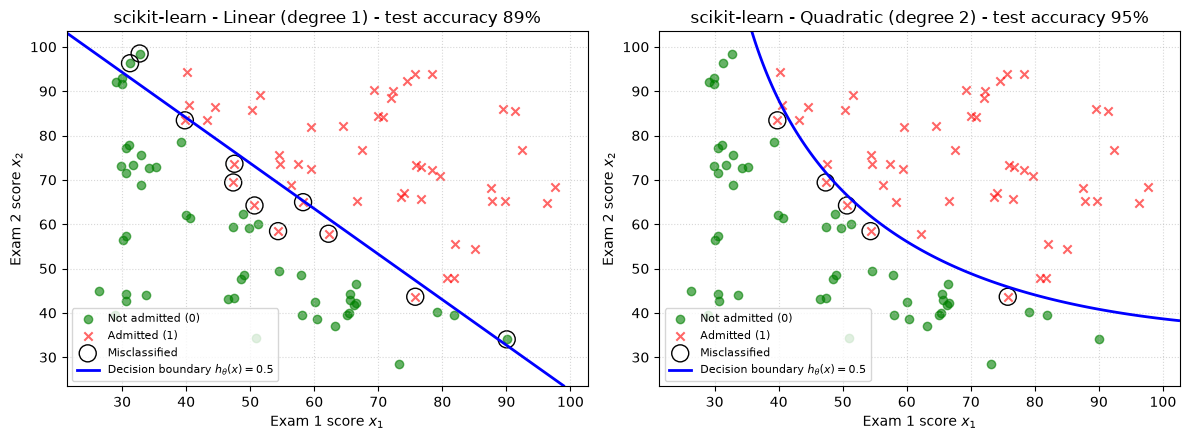

In [26]:
# Decision boundaries on the test set: h(x) = 0.5, drawn as a contour of predict_proba on a grid
# (works for any degree, unlike the closed-form line of exercise a)
x1_grid, x2_grid = np.meshgrid(
    np.linspace(x_test[:, 0].min() - 5, x_test[:, 0].max() + 5, 300),
    np.linspace(x_test[:, 1].min() - 5, x_test[:, 1].max() + 5, 300),
)
grid = np.column_stack([x1_grid.ravel(), x2_grid.ravel()])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (degree, title) in zip(axes, [(1, "Linear (degree 1)"), (2, "Quadratic (degree 2)")]):
    model = models[degree]
    proba = model.predict_proba(grid)[:, 1].reshape(x1_grid.shape)
    y_pred = model.predict(x_test)
    wrong = y_pred != y_test

    ax.scatter(x_test[y_test == 0, 0], x_test[y_test == 0, 1],
               color='green', alpha=0.6, marker='o', label='Not admitted (0)')
    ax.scatter(x_test[y_test == 1, 0], x_test[y_test == 1, 1],
               color='red', alpha=0.6, marker='x', label='Admitted (1)')
    ax.scatter(x_test[wrong, 0], x_test[wrong, 1], s=150, facecolors='none',
               edgecolors='black', label='Misclassified')
    ax.contour(x1_grid, x2_grid, proba, levels=[0.5], colors='blue', linewidths=2)
    ax.plot([], [], color='blue', lw=2, label=r'Decision boundary $h_\theta(x)=0.5$')

    ax.set_xlabel('Exam 1 score $x_1$')
    ax.set_ylabel('Exam 2 score $x_2$')
    ax.set_title(f'scikit-learn - {title} - test accuracy {np.mean(~wrong):.0%}')
    ax.legend(loc='lower left', fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [27]:
# Comparison with our own models of a., b. and c.
# StandardScaler uses the same mu and sigma as our z-norm, so for degree 1
# the weights of scikit-learn can be compared directly with our theta of a. and b.
sk_deg1 = models[1][-1]
theta_sk1 = np.concatenate((sk_deg1.intercept_, sk_deg1.coef_[0]))

# Predictions of our models and of scikit-learn
pred_test_a = (hypothesis(X_test_norm, theta) >= 0.5).astype(int)
pred_test_b = (hypothesis(X_test_norm, thetas_sga) >= 0.5).astype(int)
pred_test_c = (hypothesis(X_poly_test, theta_poly) >= 0.5).astype(int)
pred_train_c = (hypothesis(X_poly, theta_poly) >= 0.5).astype(int)
pred_test_sk1 = models[1].predict(x_test)
pred_test_sk2 = models[2].predict(x_test)
pred_train_sk2 = models[2].predict(x_train)

print("=" * 60)
print("SCIKIT-LEARN AGAINST OUR OWN MODELS".center(60))
print("=" * 60)
print("DEGREE 1 (EXERCISES a. AND b.)")
print("- Weights scikit-learn:", np.round(theta_sk1, 4))
print("- Weights a. (batch)  :", np.round(theta, 4))
print("- Weights b. (SGA)    :", np.round(thetas_sga, 4))
print(f"- J scikit-learn / a. / b.: {objective(X_train_norm, y_train, theta_sk1):.4f} / "
      f"{objective(X_train_norm, y_train, theta):.4f} / {objective(X_train_norm, y_train, thetas_sga):.4f}")
print("- Test students where scikit-learn and a. differ:", np.sum(pred_test_sk1 != pred_test_a))
print("- Test students where scikit-learn and b. differ:", np.sum(pred_test_sk1 != pred_test_b))
print("-" * 60)
print("DEGREE 2 (EXERCISE c.)")
print("- Test students where scikit-learn and c. differ    :", np.sum(pred_test_sk2 != pred_test_c))
print("- Training students where scikit-learn and c. differ:", np.sum(pred_train_sk2 != pred_train_c))
different = np.where(pred_train_sk2 != pred_train_c)[0]
for i in range(len(different)):
    n = different[i]
    print(f"- Scores ({x_train[n, 0]:.1f}, {x_train[n, 1]:.1f}), admitted = {y_train[n]}, "
          f"scikit-learn = {pred_train_sk2[n]}, c. = {pred_train_c[n]} (h = {hypothesis(X_poly[n], theta_poly):.3f})")
print("=" * 60)

            SCIKIT-LEARN AGAINST OUR OWN MODELS             
DEGREE 1 (EXERCISES a. AND b.)
- Weights scikit-learn: [1.6537 3.8561 3.5907]
- Weights a. (batch)  : [1.7184 3.9928 3.7251]
- Weights b. (SGA)    : [1.2395 2.91   2.6502]
- J scikit-learn / a. / b.: -0.2036 / -0.2035 / -0.2133
- Test students where scikit-learn and a. differ: 0
- Test students where scikit-learn and b. differ: 0
------------------------------------------------------------
DEGREE 2 (EXERCISE c.)
- Test students where scikit-learn and c. differ    : 0
- Training students where scikit-learn and c. differ: 1
- Scores (82.2, 42.7), admitted = 0, scikit-learn = 0, c. = 1 (h = 0.506)


The handout asks for `loss="log"`, but recent versions of scikit-learn no longer accept this name. The same loss is now called `"log_loss"`, so we used it.

With degree 1, scikit-learn gets 89 of 100 on the training set and on the test set.
On the test set it gives the same prediction as our models of exercises a and b for every student.
Its weights (1.6537, 3.8561, 3.5907) are close to the ones of exercise a (1.7184, 3.9928, 3.7251), and its J is -0.2036 against -0.2035.

With degree 2, scikit-learn gets 95 of 100 on the test set, like our model of exercise c, again with the same prediction for every test student.
On the training set scikit-learn gets 100 and c gets 99.
The only difference is the refused student at (82.2, 42.7). Our model of c puts this student just on the wrong side, with $h_\theta(x) = 0.506$.
This time the training reaches `max_iter` (5 000 epochs), while with degree 1 it stopped by itself after 390 epochs.
As in c, the training set can be separated without a mistake, so J has no maximum, and with `penalty=None` nothing stops the weights from growing.